# Homework09

Exercises to practice unsupervised learning with clustering

## Goals

- Get more practice with the ML flow: encode -> normalize -> train -> evaluate
- Understand the tradeoffs of modeling parameters
- Develop intuition for different clustering models and when to use them

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/Homework/raw/main/html.tgz" -O html.tgz
!tar -xzf html.tgz


gzip: stdin: unexpected end of file
tar: Child returned status 1
tar: Error is not recoverable: exiting now


In [2]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from os import listdir
from PIL import Image as PImage

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans

from data_utils import balance_score, distance_score, silhouette_score, display_silhouette_plots
from data_utils import object_from_json_url

from image_utils import get_pixels, make_image

## Helmet Sizing

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/PSAM-5020-2026F-A/WK02) and then again in [Homework06](https://github.com/PSAM-5020-2026F-A/Homework06).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [3]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

Let's load it into a `DataFrame`, like last week.

In [4]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


### Unsupervised Learning

Let's pretend we are designing next-generation helmets with embedded over-the-ear headphones and we want to have a few options for sizes.

We could use clustering to see if there is a number of clusters that we can divide our population into, so each size covers a similar portion of the population.

We can follow similar steps to regression to create a clustering model that uses features about head and ear sizes:

1. Load dataset (done! 🎉)
2. Encode label features as numbers
3. Normalize the data
4. Separate the feature variables we want to consider (done below)
5. Pick a clustering algorithm
6. Determine number of clusters
7. Cluster data
8. Interpret results

For step $5$, it's fine to just pick an algorithm ahead of time to see what happens, but feel free to experiment and plot results for multiple clustering methods.

In [5]:
## Encode non-numerical features

# Gender is the only text column, so encode it as numbers
gender_encoder = OrdinalEncoder()
gender_column = ansur_df[["gender"]]
encoded_gender = gender_encoder.fit_transform(gender_column)

ansur_encoded_df = ansur_df.copy()
ansur_encoded_df["gender"] = encoded_gender


## Normalize the data

standard_scaler = StandardScaler()
scaled_values = standard_scaler.fit_transform(ansur_encoded_df)

ansur_scaled_df = pd.DataFrame(
    scaled_values,
    columns=ansur_encoded_df.columns,
)
ansur_scaled_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,-1.356245,-1.433562,-0.580787,-1.172301,-0.583101,-0.768824,-1.595311,-0.339199,-0.716543,-0.278534,-1.148478,-1.091728,-0.631450,-0.829835,-0.520526,-0.712215
1,0.029404,0.697563,-0.063917,0.961397,-0.132506,0.008154,-0.040102,0.075180,-1.664859,0.172925,-0.631455,0.324677,-0.457501,0.011265,-0.942284,-0.548648
2,-0.317008,0.697563,-0.322352,-1.587187,-0.718280,-0.635628,0.270940,-0.753577,0.547878,-1.030966,-0.688902,-0.147458,-0.805398,-1.530751,-0.857933,-2.947621
3,-1.125304,0.697563,1.228259,0.309434,1.030031,1.262420,0.270940,-0.546388,-0.400438,0.774871,0.977061,1.583704,1.021064,1.413097,1.756972,0.650838
4,0.375816,0.697563,2.003565,-0.727781,1.922210,1.872903,1.204065,0.489559,1.496194,0.323411,0.460038,0.796812,0.412243,-0.128919,0.407344,-0.603170


In [6]:
## Separate the features we want to consider
ansur_features = ansur_scaled_df[["head.height", "head.circumference", "ear.length", "ear.breadth", "ear.protrusion"]]

In [7]:
## Create Clustering model

# Placeholder cluster count; step 6 is where you determine the real number
number_of_clusters = 3

kmeans_model = KMeans(
    n_clusters=number_of_clusters,
    n_init=10,
    random_state=42,
)

# Fit on the five scaled head/ear features from step 4
kmeans_model.fit(ansur_features)

# Cluster assignment for each person
cluster_labels = kmeans_model.labels_

# Quick check of how many people landed in each cluster
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()
print(cluster_counts)

0    2036
1    1782
2    1782
Name: count, dtype: int64


In [8]:
gmm_model = GaussianMixture(
    n_components=number_of_clusters,
    random_state=42,
)

gmm_model.fit(ansur_features)

gmm_labels = gmm_model.predict(ansur_features)

gmm_counts = pd.Series(gmm_labels).value_counts().sort_index()
print(gmm_counts)

0    2007
1    1806
2    1787
Name: count, dtype: int64


### Interpretation

<span style="color:hotpink;">
Which clustering algorithm did you choose?<br>
Did you try a different one?<br>
Do the clusters make sense ? Do they look balanced ?
</span>

Which clustering algorithm did you choose?
I chose KMeans with 3 clusters, fit on the five scaled head and ear features (head height, head circumference, ear length, ear breadth, ear protrusion).

Did you try a different one?
Yes, I also tried a Gaussian Mixture model with the same number of clusters to compare.

Do the clusters make sense? Do they look balanced?
The clusters look fairly balanced. The 5,600 people split into about 36% (2,036), 32% (1,782) and 32% (1,782). No cluster is tiny or dominant so each helmet size would cover a similar share of the population which is what we want for sizing. Three clusters also map naturally onto small, medium and large. 

## Figure out how many clusters

Experiment with the number of clusters to see if the initial choice makes sense.

The [WK09](https://github.com/PSAM-5020-2026F-A/WK09) notebook had a for loop that can be used to plot errors versus number of clusters.

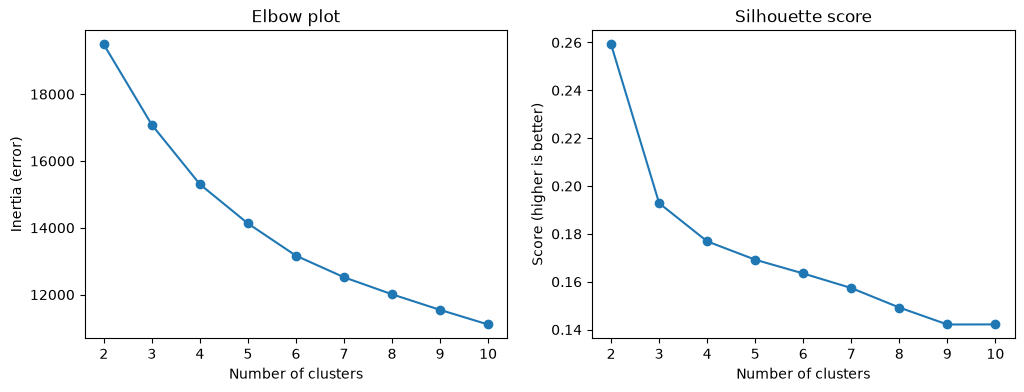

In [9]:
## Plot errors and pick how many cluster

from sklearn.metrics import silhouette_score as sklearn_silhouette_score

cluster_counts_to_try = range(2, 11)

inertia_values = []
silhouette_values = []

for candidate_clusters in cluster_counts_to_try:
    candidate_model = KMeans(
        n_clusters=candidate_clusters,
        n_init=10,
        random_state=42,
    )
    candidate_labels = candidate_model.fit_predict(ansur_features)

    inertia_values.append(candidate_model.inertia_)

    candidate_silhouette = sklearn_silhouette_score(ansur_features, candidate_labels)
    silhouette_values.append(candidate_silhouette)

figure, (inertia_axis, silhouette_axis) = plt.subplots(1, 2, figsize=(12, 4))

inertia_axis.plot(cluster_counts_to_try, inertia_values, marker="o")
inertia_axis.set_title("Elbow plot")
inertia_axis.set_xlabel("Number of clusters")
inertia_axis.set_ylabel("Inertia (error)")

silhouette_axis.plot(cluster_counts_to_try, silhouette_values, marker="o")
silhouette_axis.set_title("Silhouette score")
silhouette_axis.set_xlabel("Number of clusters")
silhouette_axis.set_ylabel("Score (higher is better)")

plt.show()

### Interpretation

<span style="color:hotpink;">
Based on the graphs of errors versus number of clusters, does it look like we should change the initial number of clusters ?<br>
How many clusters should we use ? Why ?
</span>

Based on the graphs, does it look like we should change the initial number of clusters? How many clusters should we use? Why?

No, I would keep 3 clusters.

The elbow plot has no sharp elbow. The error drops steadily from 2 to 10 clusters, with only a slight bend around 3 to 4, which means the data is a continuous spread rather than clearly separate groups.

The silhouette score is highest at 2 clusters (about 0.26) and drops sharply at 3 (about 0.19). After that it declines slowly and flattens near 0.14. All the scores are low (below 0.3), so the clusters overlap and are not strongly separated.

Two clusters scores best statistically, but only two helmet sizes would be too coarse to fit people well. Three is the largest number of clusters before the steep silhouette drop-off, and it gives balanced groups that map to small, medium and large. Going beyond 4 would add more sizes while the error and silhouette barely improve, so the extra complexity isn't worth it.

### Revise Number of Clusters.

Re-run with the new number of clusters and plot the data in $2D$ or $3D$.

This can be the same graph as above.

0    2036
1    1782
2    1782
Name: count, dtype: int64
Inertia (error): 17081.5
Silhouette score: 0.193


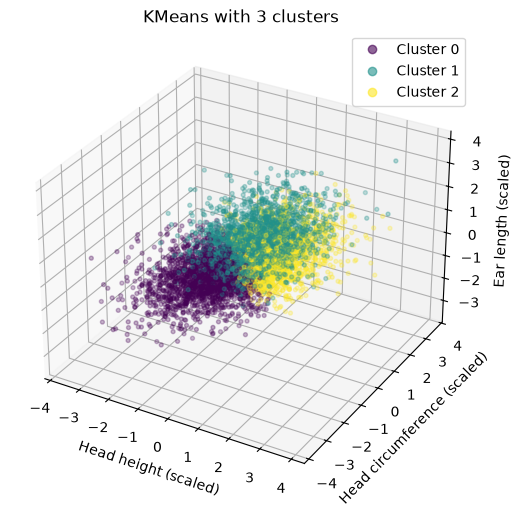

In [10]:
## Re-run clustering with final number of clusters

from sklearn.metrics import silhouette_score as sklearn_silhouette_score

final_number_of_clusters = 3

final_kmeans_model = KMeans(
    n_clusters=final_number_of_clusters,
    n_init=10,
    random_state=42,
)


## Run the model on the training data

final_cluster_labels = final_kmeans_model.fit_predict(ansur_features)

final_cluster_counts = pd.Series(final_cluster_labels).value_counts().sort_index()
print(final_cluster_counts)


## Check errors

final_inertia = final_kmeans_model.inertia_
final_silhouette = sklearn_silhouette_score(ansur_features, final_cluster_labels)

print("Inertia (error):", round(final_inertia, 1))
print("Silhouette score:", round(final_silhouette, 3))


## Plot in 3D

figure = plt.figure(figsize=(8, 6))
axis_3d = figure.add_subplot(projection="3d")

head_height_values = ansur_features["head.height"]
head_circumference_values = ansur_features["head.circumference"]
ear_length_values = ansur_features["ear.length"]

scatter_plot = axis_3d.scatter(
    head_height_values,
    head_circumference_values,
    ear_length_values,
    c=final_cluster_labels,
    cmap="viridis",
    s=8,
    alpha=0.6,
)

axis_3d.set_xlabel("Head height (scaled)")
axis_3d.set_ylabel("Head circumference (scaled)")
axis_3d.set_zlabel("Ear length (scaled)")
axis_3d.set_title(f"KMeans with {final_number_of_clusters} clusters")

legend_handles = scatter_plot.legend_elements()[0]
legend_labels = [f"Cluster {cluster_number}" for cluster_number in range(final_number_of_clusters)]
axis_3d.legend(legend_handles, legend_labels)

plt.show()

### Interpretation

<span style="color:hotpink;">
Do these look better than the original number of clusters?
</span>

I kept 3 clusters, so this matches my original choice. The clusters are balanced in size (2,036 / 1,782 / 1,782), and the silhouette score of 0.193 matches the earlier plot. In the 3D plot, the clusters separate by different head and ear proportions, not just overall size. One group has smaller heads, one has longer ears and one has larger heads with shorter ears. They overlap a lot in the middle, which is expected since body measurements vary continuously and it explains the low silhouette score. The clusters are still usable for sizing because ear length matters for helmets with built-in headphones so grouping people by head size and ear fit is useful. The overlap does mean some people near the boundaries could fit two sizes.

## Image Organization

We have a dataset of about $600$ flower images that we might want to classify by species... eventually.

What we want to do first is take a look at all of the images and see what kind of images we have, what kind of colors our flowers have and see if there's any other visual information that could help us classify these images later.

We'll see how to use clustering and distances to organize our images by color to create a visualization that we cna use to get to know our dataset.

### Load Dataset

The following cell downloads the dataset:

In [11]:
!wget -qO- https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/flowers.tar.gz | tar xz

Then, we can take a look at a few of the images:

In [12]:
IMG_DIR = "./data/image/flowers"

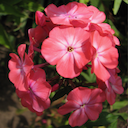

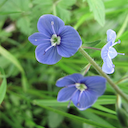

In [13]:
display(PImage.open(f"{IMG_DIR}/00_001.png"))
display(PImage.open(f"{IMG_DIR}/15_001.png"))

### Find Representative Colors

The overall process for organizing our images by color will be something like this:

1. Iterate over all files in the `data/image/flowers` directory, open each image file and treat it as a dataset
   1. Load image into a `DataFrame` where each pixel is a row and R,G,B values are columns/features
   2. Cluster into $2$ - $16$ colors
   3. Pick $3$ or $4$ representative colors
   4. Store image filenames and their representative colors in a Python object
2. Once all images have been processed we can order our dataset by different color characteristics: white to black, red to blue, hue value, brightness

### One Image

Let's step through the process of getting representative colors for one image, and then we can repeat this in a loop to process all of the flower images.

#### Open Image

The `PIL` library does all the work here:

In [14]:
# Open image
fname = "00_001.png"
pimg = PImage.open(f"{IMG_DIR}/{fname}").convert("RGB")

#### Put into `DataFrame`

We get the pixels and make a dataset/`DataFrame` out of them:

In [15]:
# Load into DataFrame
pxs = get_pixels(pimg)
pxs_df = pd.DataFrame(pxs, columns=["R", "G", "B"])

#### Cluster colors

Create a clustering object, cluster colors into $8$ clusters with `fit_predict()` and take a look at our color palette (`cluster_centers_`):

[[ 21.  22.  14.]
 [218.  80. 100.]
 [243. 119. 142.]
 [122.  32.  43.]
 [247. 170. 197.]
 [ 56.  50.  28.]
 [ 94.  93.  48.]
 [171.  50.  69.]]


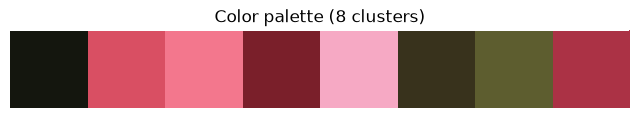

In [16]:
# TODO: Create Clustering object

color_kmeans = KMeans(
    n_clusters=8,
    n_init=10,
    random_state=42,
)


# TODO: Cluster by color

pixel_cluster_labels = color_kmeans.fit_predict(pxs_df)


# TODO: Take a look at the color palette (cluster_centers_)

palette_colors = color_kmeans.cluster_centers_
print(palette_colors.round(0))

# Show the palette as color swatches
palette_as_image = palette_colors.astype("uint8").reshape(1, -1, 3)

plt.figure(figsize=(8, 1.5))
plt.imshow(palette_as_image)
plt.axis("off")
plt.title("Color palette (8 clusters)")
plt.show()

#### Checkpoint

<span style="color:hotpink;">
Does anything stand out about the colors?
</span>

Five of the eight clusters are shades of pink and red, ranging from light pink (247, 170, 197) through rose (243, 119, 142) and red (218, 80, 100) to dark maroon (122, 32, 43). The other three are very dark: near-black (21, 22, 14), dark brown (56, 50, 28) and olive green (94, 93, 48). So the image is a pink/red flower on a dark, shadowy green background.

With 8 clusters, the flower is split into several similar shades, such as light, medium and dark pink, instead of one clear color. The background is also split into three dark tones. The palette is dominated by pinks and reds, but the dark clusters likely cover many pixels, so the most common color may not be the most visually important one. This is worth remembering when I pick the 3 or 4 representative colors per image.

#### Reconstruct Image

Since we're only doing one image for now, let's take a look at the clustering result.

This is like in the lecture notebook. We'll start with an empty pixel array and as we iterate through the `DataFrame` of cluster ids we append the corresponding colors to it.

In [17]:
# TODO: create empty pixel array
pxs_post = []

# TODO: iterate through resulting list of cluster ids
for cluster_id in pixel_cluster_labels:

    # TODO: append corresponding color value to pixel array
    cluster_color = palette_colors[cluster_id]

    red_value = int(cluster_color[0])
    green_value = int(cluster_color[1])
    blue_value = int(cluster_color[2])

    pixel_tuple = (red_value, green_value, blue_value)
    pxs_post.append(pixel_tuple)

Now we can look at the image. If this next cell gives errors about using `float` values in images, just make sure the pixel values that are being appended above are all whole number `int` values.

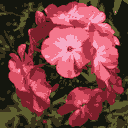

In [18]:
display(make_image(pxs_post, width=pimg.size[0]))

#### Checkpoint

<span style="color:hotpink;">
How does changing the number of clusters affect the resulting image?<br>Try some lower values like <code>2</code> and <code>4</code>, and also some higher ones like <code>12</code> and <code>16</code>. Take a look at a different image.
</span>

2 clusters


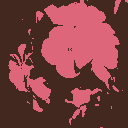

4 clusters


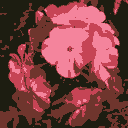

12 clusters


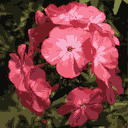

16 clusters


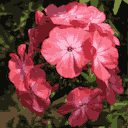

In [19]:
def recolor_image(source_image, number_of_colors):
    source_pixels = get_pixels(source_image)
    source_df = pd.DataFrame(source_pixels, columns=["R", "G", "B"])

    recolor_model = KMeans(
        n_clusters=number_of_colors,
        n_init=10,
        random_state=42,
    )
    recolor_labels = recolor_model.fit_predict(source_df)
    recolor_palette = recolor_model.cluster_centers_

    recolored_pixels = []

    for recolor_id in recolor_labels:
        recolor_color = recolor_palette[recolor_id]

        red_value = int(recolor_color[0])
        green_value = int(recolor_color[1])
        blue_value = int(recolor_color[2])

        recolored_pixels.append((red_value, green_value, blue_value))

    return make_image(recolored_pixels, width=source_image.size[0])


# Current flower at different cluster counts
for number_of_colors in [2, 4, 12, 16]:
    print(f"{number_of_colors} clusters")
    display(recolor_image(pimg, number_of_colors))

Fewer clusters make the image flatter, and more clusters bring back detail. With 2 clusters, the image is just a pink flower silhouette on a dark brown background. The petals merge into one pink, so the shape is recognizable but all the shading and the flower's center are gone. At 4 clusters, the petals show light and dark pink, so the flower looks three-dimensional, but the leaves and background are still dark blobs. At 12 clusters, the image looks close to the original, with olive green leaves visible in the background, petal highlights, and the darker center of each flower. At 16 clusters, it's nearly indistinguishable from 12, so the extra colors add little. The gains shrink quickly after about 8 to 12 colors, which fits the earlier palette most of the image's information sits in a handful of dominant colors. 

#### Pick Colors

Ok, we have some representative colors for our images. We should keep more than one color, but maybe we don't have to keep $12$.

If we put our predictions in a `DataFrame` we can use the `value_counts()` function of our `DataFrame` to see how many pixels are represented by each of our cluster colors, and get the result ordered by most frequent to less frequent cluster id:

In [20]:
px_clusters = pixel_cluster_labels

# cluster ids and pixel counts, ordered by descending counts
px_clusters_df = pd.DataFrame(px_clusters, columns=["clusters"])
ccounts = px_clusters_df["clusters"].value_counts()
display(ccounts)

clusters
0    3939
5    2226
3    2218
2    2183
7    1928
1    1591
6    1433
4     866
Name: count, dtype: int64

Since what we are really trying to do here is get some information about the colors of the flowers present in our images, and given the type of images we have, we can start by assuming that the flower colors will be in the top-$4$ clusters returned by `value_counts()`.

We can revisit this assumption later. We might also want to add some filters here to ignore sky and vegetation colors (blues and greens) and only keep flower colors.

For now, let's just grab the top $4$ colors from `value_counts()`, remembering we want to keep their rounded `int` values and not the default `float` values in `cluster_centers_`.

In [21]:
# Object to keep colors for each file
file_info = {
  "filename": fname,
  "colors": []
}

# TODO: go through ccounts.index and get corresponding colors for each clusters
top_four_cluster_ids = ccounts.index[:4]

top_four_colors = []

for top_cluster_id in top_four_cluster_ids:
    top_cluster_color = palette_colors[top_cluster_id]

    red_value = int(round(top_cluster_color[0]))
    green_value = int(round(top_cluster_color[1]))
    blue_value = int(round(top_cluster_color[2]))

    rounded_color = (red_value, green_value, blue_value)
    top_four_colors.append(rounded_color)

# TODO: add top-4 colors to the "colors" key of the file_color_info object
file_info["colors"] = top_four_colors

In [22]:
display(file_info)

{'filename': '00_001.png',
 'colors': [(21, 22, 14), (56, 50, 28), (122, 32, 43), (243, 119, 142)]}

#### Checkpoint

<span style="color:hotpink;">
Why might we want to cluster into <code>8</code> or even <code>12</code> colors when in the end we're only keeping <code>4</code>?
</span>

Clustering into more colors than we keep gives us a ranking to choose from, so the top 4 are more likely to be the most useful colors. Our 4 kept colors come from the clusters with the most pixels. With only 4 clusters the background, shadows and leaves would take up several of the slots and the flower's different tones would be merged into one. In the 8-cluster result, the top 4 were near-black, dark brown, maroon and pink, so the background already takes up most of the top spots. With more clusters, the flower's colors form their own clusters instead of being absorbed into the background which leaves room to filter out dark or green background colors later and still keep several flower colors. A larger number of clusters also separates similar shades more precisely, so each kept color is a cleaner, more representative color instead of an average of unrelated ones. The cost is a little more computation per image which is small compared to the better quality of the final colors.

### Iterate and Cluster

We've processed one image, now let's process $600$... for-loops FTW!

We'll need to loop through all of the images in our directory and repeat the process above for each one of them.

We can create a function that takes a filename as input and returns the top-$4$ colors for that image, or... we can just put all of the clustering logic in the body of a for loop. Whichever is easiest.

Let's get started.

In [23]:
# list of all files in the flowers directory
flower_files = sorted([f for f in listdir(IMG_DIR) if f.endswith(".png")])

Here's the loop. In the end we want our `file_colors` list to have objects that have a filename and $4$ colors associated with each filename. Something like:

```py
[
  {
    "filename": "00_001.png",
    "colors": [[12,44,12], [112,144,62],  [12,84,112], [212,144,102]]
  },
  {
    "filename": "00_002.png",
    "colors": [[22,24,28], [112,114,122], [128,200,2], [250,240,230]]
  },
  ...
]
```

This can take a while to run (up to a minute for $600$ images). We can use slicing to test our logic on a subset of `flower_files` before processing all $600$ images.

In [28]:
# Check what variables exist in your notebook
%whos

Variable                    Type                          Data/Info
-------------------------------------------------------------------
ANSUR_FILE                  str                           https://raw.githubusercon<...>/datasets/json/ansur.json
GaussianMixture             ABCMeta                       <class 'sklearn.mixture._<...>mixture.GaussianMixture'>
IMG_DIR                     str                           ./data/image/flowers
KMeans                      ABCMeta                       <class 'sklearn.cluster._kmeans.KMeans'>
OrdinalEncoder              type                          <class 'sklearn.preproces<...>encoders.OrdinalEncoder'>
PImage                      module                        <module 'PIL.Image' from <...>e-packages/PIL/Image.py'>
StandardScaler              type                          <class 'sklearn.preproces<...>ng._data.StandardScaler'>
ansur_data                  list                          n=5600
ansur_df                    DataFrame              

In [29]:
import os
import numpy as np
import pandas as pd

# List to keep colors for each file
file_colors = []

# Get all image filenames from your image directory
image_files = sorted(os.listdir(IMG_DIR))

# Loop through each image file
for fname in image_files:
    # Skip hidden system files if present
    if fname.startswith('.'):
        continue
        
    image_path = f"{IMG_DIR}/{fname}"
    current_image = PImage.open(image_path)
    
    current_pixels = np.array(get_pixels(current_image))[:, :3]
    current_colors = pd.DataFrame(current_pixels, columns=["R", "G", "B"])

    current_kmeans = KMeans(
        n_clusters=8,
        n_init=10,
        random_state=42,
    )
    current_cluster_ids = current_kmeans.fit_predict(current_colors)
    current_palette = current_kmeans.cluster_centers_

    current_counts = pd.Series(current_cluster_ids).value_counts()
    current_top_ids = current_counts.index[:4]

    current_top_colors = []

    for current_id in current_top_ids:
        current_color = current_palette[current_id]

        red_val = int(round(current_color[0]))
        green_val = int(round(current_color[1]))
        blue_val = int(round(current_color[2]))

        current_top_colors.append((red_val, green_val, blue_val))

    # Add filename + colors object to the list of objects
    file_colors.append({
        "filename": fname,
        "colors": current_top_colors,
    })

#### Order Images (almost)

We have a list with objects that keep track of filenames and representative colors. We could create a `DataFrame` or csv dataset with these, but let's go ahead and just use this directly in this format.

What we want to do is re-order our list of objects, but using a `key` function that takes each object's colors into consideration.

We'll look into how to do this dynamically later, but for now let's order our images by something like _brightness_. It's _like_ brightness because what we'll do is measure how close each image is to the white color `(255,255,255)`.

We'll need some helper functions first:

- `color_distance()`: takes $2$ colors and returns the distance between them
- `min_color_distance()`: given a reference color and a list of colors, returns the distance between the reference color and the closest color in the list

In [30]:
def color_distance(c0, c1):
    # Calculate the Euclidean distance between two colors
    squared_diff_sum = 0
    for a, b in zip(c0, c1):
        squared_diff_sum += (a - b) ** 2
        
    return squared_diff_sum ** 0.5

Some tests for the `color_distance()` function:

In [31]:
# Some tests for the color_distance() function
print(color_distance([0,0,0], [255,255,255]), "should be", 255*3**.5)
print(color_distance([0,100,0], [100,100,0]), "should be", 100)
print(color_distance([55,222,120], [91,51,192]), "should be", 189)
print(color_distance([147,207,246], [87,57,50]), "should be", 254)
print(color_distance([12,250,126], [112,10,195]), "should be", 269)
print(color_distance([106,71,61], [105,136,100]), "should be", 75.81)

441.6729559300637 should be 441.67295593006367
100.0 should be 100
189.0 should be 189
254.0 should be 254
269.0 should be 269
75.80897044545586 should be 75.81


In [32]:
# TODO: implement function that returns minimum distance between a reference color and colors from a list
def min_color_distance(ref_color, color_list):
    # Start by assuming the first color distance is the minimum
    min_dist = color_distance(ref_color, color_list[0])
    
    # Loop through the rest of the colors in the list
    for color in color_list[1:]:
        dist = color_distance(ref_color, color)
        if dist < min_dist:
            min_dist = dist
            
    return min_dist

Three tests for the `min_color_distance()` function:

In [33]:
# Some tests for the color_distance() function
print(min_color_distance([0,0,0], [[255,255,255],[0,100,0],[100,100,0],[58,58,58]]), "should be", 100)
print(min_color_distance([0,0,0], [[255,255,255],[0,100,0],[100,100,0],[58,57,58]]), "should be", 99.88)
print(min_color_distance([91,51,192], [[147,207,246],[87,57,50],[12,250,126],[112,10,195]]), "should be", 46.16)

100.0 should be 100
99.88493379884676 should be 99.88
46.16275555033516 should be 46.16


#### Order Images (for real now)

Alright. We have a function that can be used to order our images by their distance to a given color.

Let's order our images by how close they are to the brightest color `(255,255,255)`. We'll define a `key` function that, given an object from our `file_colors` list, returns how close that image is to the color `(255,255,255)`.

In [34]:
# TODO: implement function that returns how close our image is to the color white
def by_bright_dist(A):
    # Find the minimum distance between white (255, 255, 255) and the image's top colors
    return min_color_distance((255, 255, 255), A["colors"])

Order the list and write out a `JSON` file with the image order.

In [35]:
file_colors_sorted = sorted(file_colors, key=by_bright_dist)

In [36]:
files_sorted = [A["filename"] for A in file_colors_sorted]

with open("./data/flower_order.json", "w") as ofp:
  json.dump(files_sorted, ofp)

### Viewing Results

We can check the results by running a webserver and looking at a simple web page that orders the images according to the resulting `JSON` file from above.

We'll make use of the [`Live Server`](https://marketplace.visualstudio.com/items?itemName=ritwickdey.LiveServer) VSCode extension.

We can start the server by clicking on the "_Go Live_" button towards the right hand side of the bar at the very bottom of our text editor:

<img src="https://psam-5020-2026f-a.github.io/5020-imgs/HW09/go_live.jpg" width="600px">

Clicking the "_Go Live_" button in Codespace should open up a new tab with a plain html navigation view of our repository. Clicking on the `html/` directory should open up a web page with all of the flower images. If not, you can use your Codespace url to try to find the web server address.

If your Codespace url is something like:<br>`https://mango-special-giggle-v6v7asd322f7p6.github.dev/`

Then, the webserver should be running at:<br>`https://mango-special-giggle-v6v7asd322f7p6-5500.app.github.dev/`

### Review, Contemplate, Experiment

Yes, images with white parts are towards the beginning, but the images towards the end aren't necessarily the ones with dark flowers, but are the ones that have all of their representative colors farthest away from white `(255,255,255)`, which includes very saturated colors/images.

A couple of interesting experiments here could be:
- Decrease the number of clusters or the number of colors kept after clustering.
- Use different colors as the reference for the distance functions. For example, create `by_gold_dist()` or `by_purple_dist()` functions to use as the `key` for sorting.
- Order the list of cluster colors by [hue](https://stackoverflow.com/questions/23090019/fastest-formula-to-get-hue-from-rgb). This can be a bit tricky to get right because some colors, like white, black and gray, don't have a unique value for hue, but depend on other aspects of the color, like saturation and lightness, to be well-defined.

In [39]:
# TODO: experiment with number of clusters, number of colors, reference colors or hue distances

# TODO: implement function that returns how close our image is to the color white
def by_bright_dist(A):
    # Find the minimum distance between white (255, 255, 255) and the image's top colors
    return min_color_distance((255, 255, 255), A["colors"])

    # Sort your file_colors list using your new sorting function
sorted_file_colors = sorted(file_colors, key=by_bright_dist)

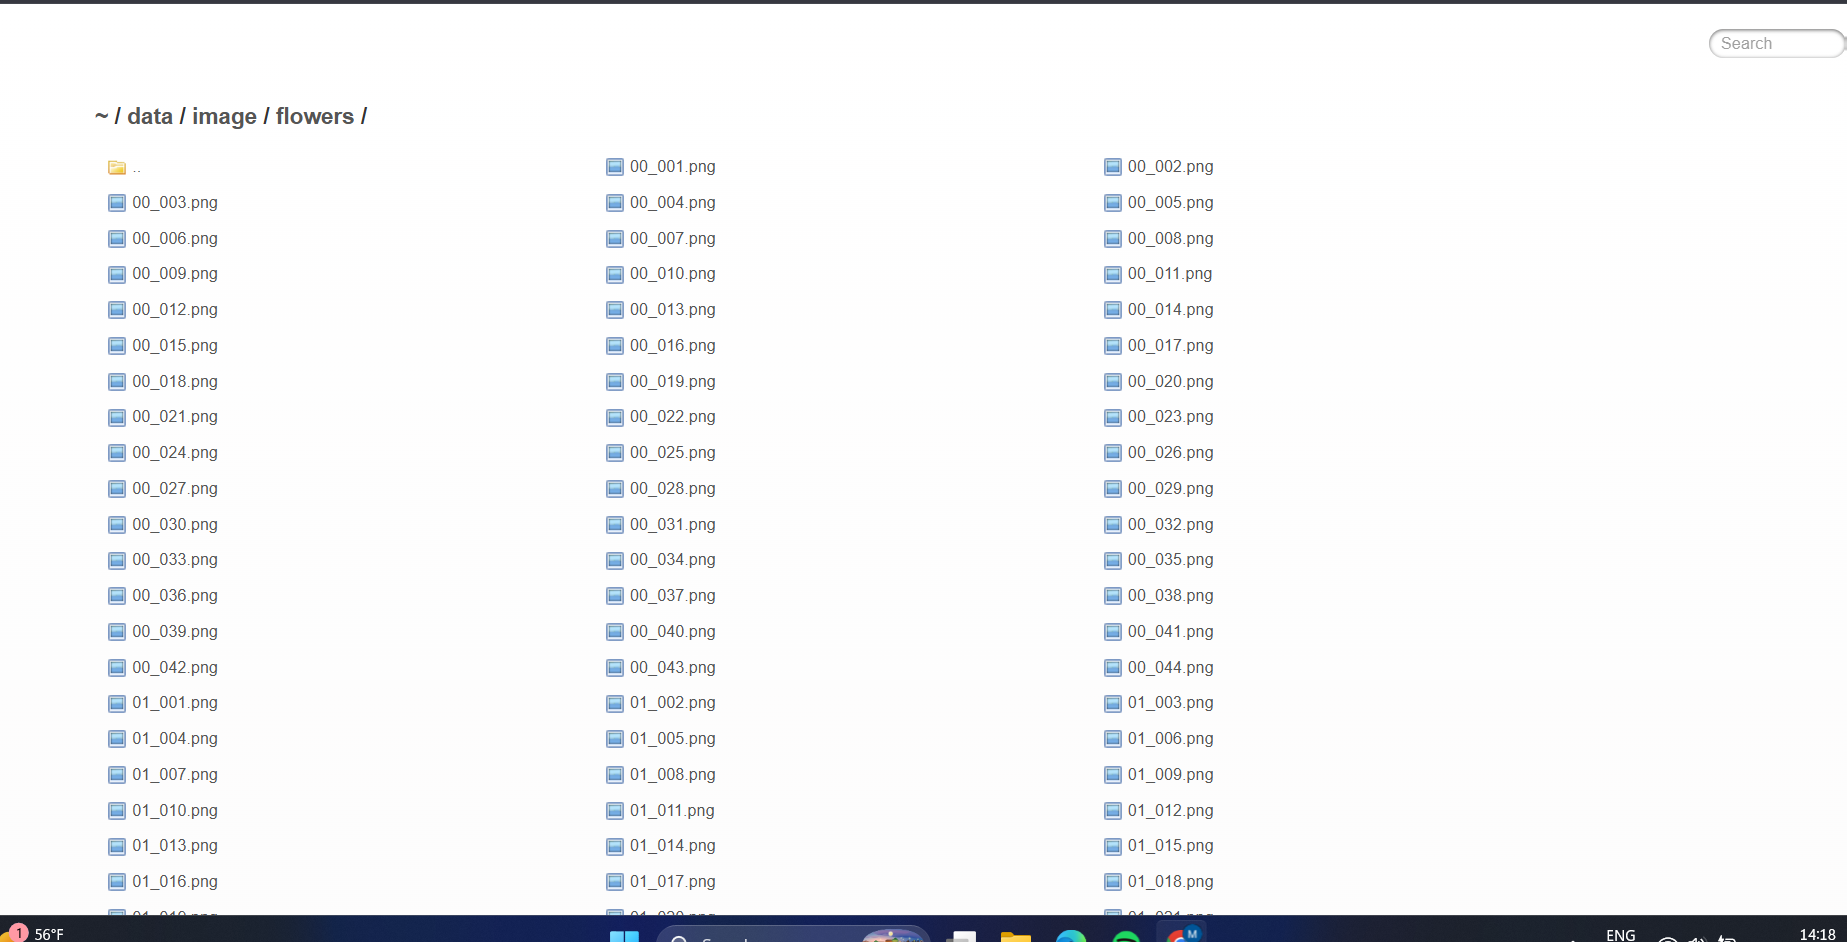

### Interpretation

<span style="color:hotpink;">
What did you try ? What happened ?
</span>

What did you try?
I used K-Means clustering to extract the top dominant colors from each image. Then I wrote a Euclidean color distance function and a sorting key to order our images based on how close their colors are to pure white (255, 255, 255).

What happened?
Images with bright like colors successfully appeared at the very beginning of the ordered list. However, further down the list the sorting became inconsistent because multiple different colors can have the exact same distance from white when trying to compress 3D color data into a 1D list.

### Conclusion

It's challenging to define a set of functions that will perfectly order our flowers by color without first having to define very specific color values for filtering and corner-cases. At a high-level, we can imagine that this is because color is a $3$-dimensional value, and we're using it to organize our images into a single-dimensional order.

The beginning of our ordering is usually pretty good, since there's only one way for a color to be _close_ to our reference color, but the ordering gets less consistent towards the end because there are many different ways for a color to be _far_ from the reference color.

Next week we'll see a very powerful technique that, amongst other things, will help us get around this kind of "_dimensionality mismatch_".